# Example of the aitlas toolbox in the context of object detection 

## Import the required packages

In [ ]:
from aitlas.datasets import ArtifiVePotsdamDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Original splits

Total number of patches: 2400


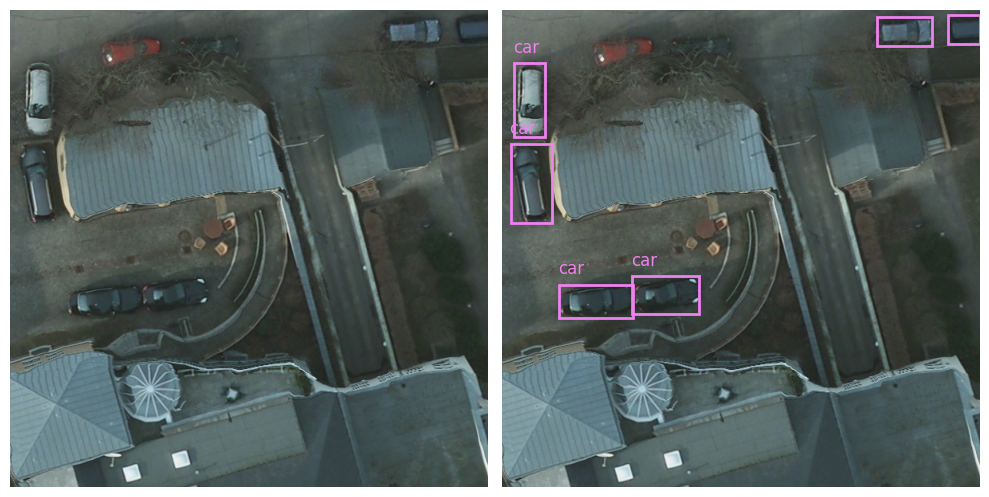

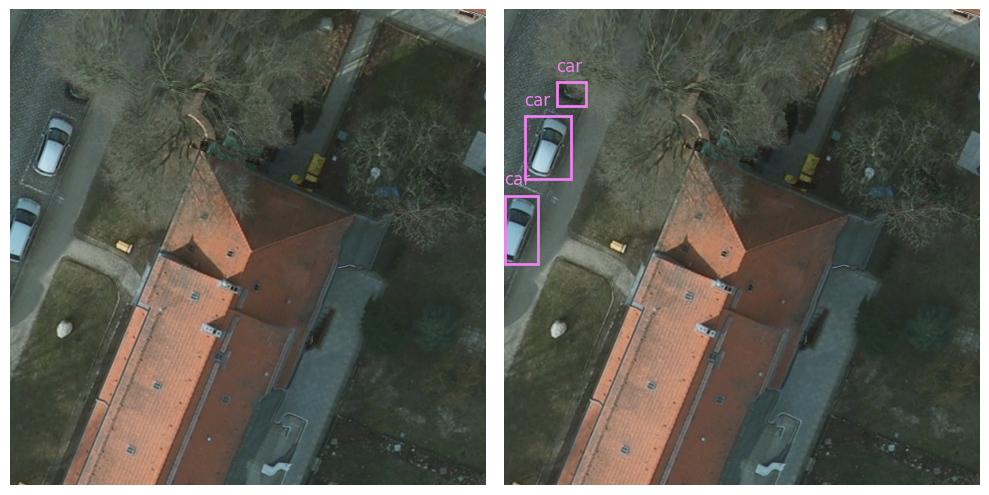

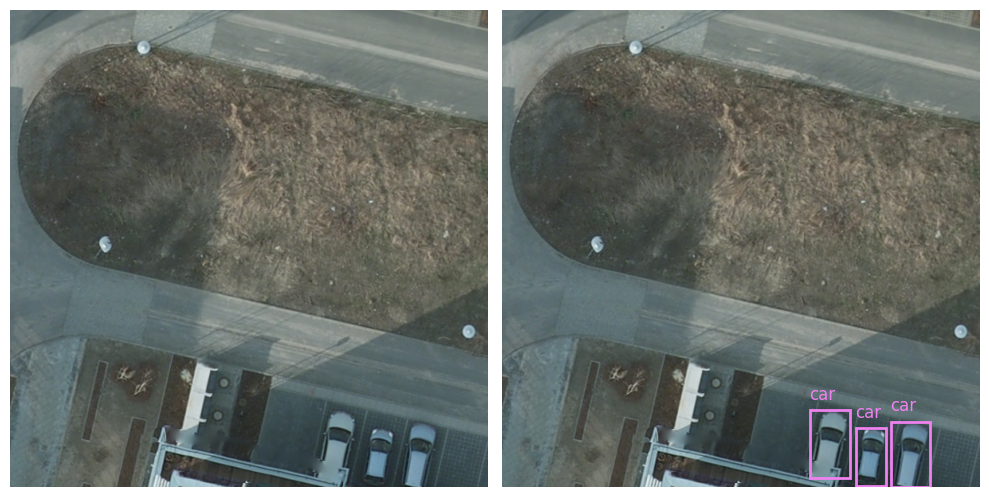

In [20]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/training/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/training/annotations_training_patches.json",
    "selection": "all", # keep all images
}
dataset = ArtifiVePotsdamDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1005)
dataset.show_image(10)
dataset.show_image(200);

New 60/20/20 splits

Total number of patches: 2280


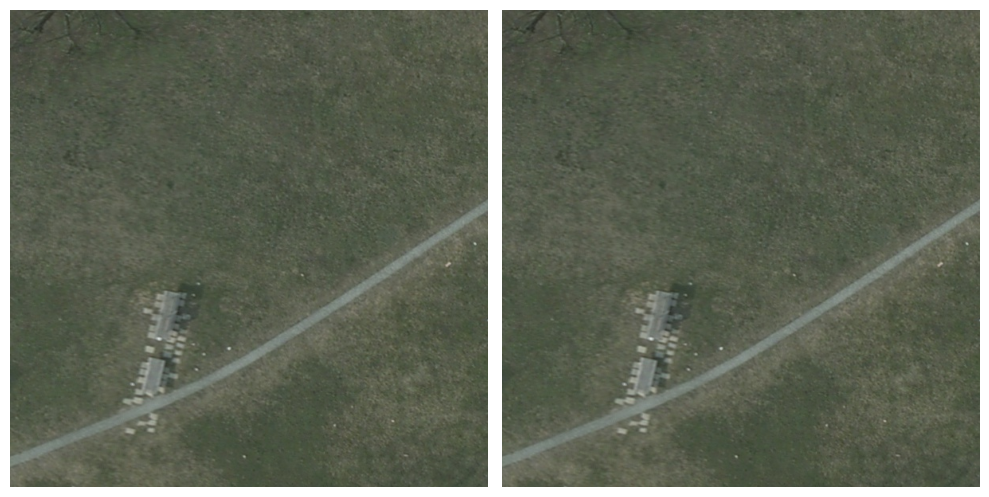

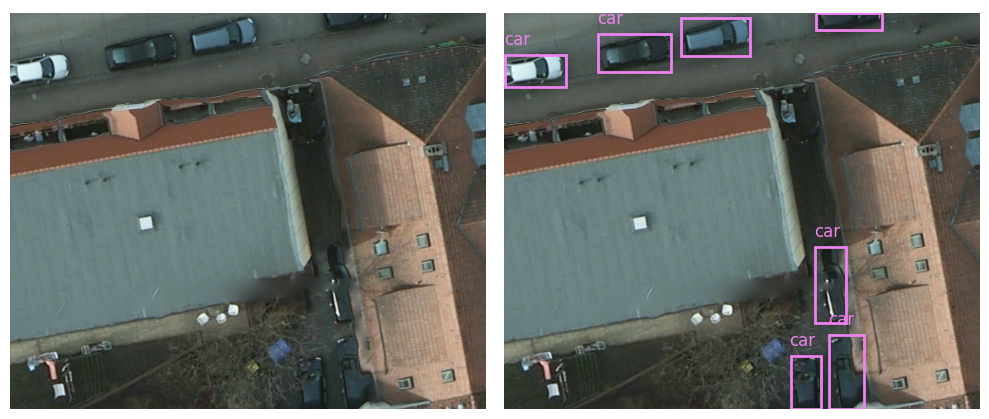

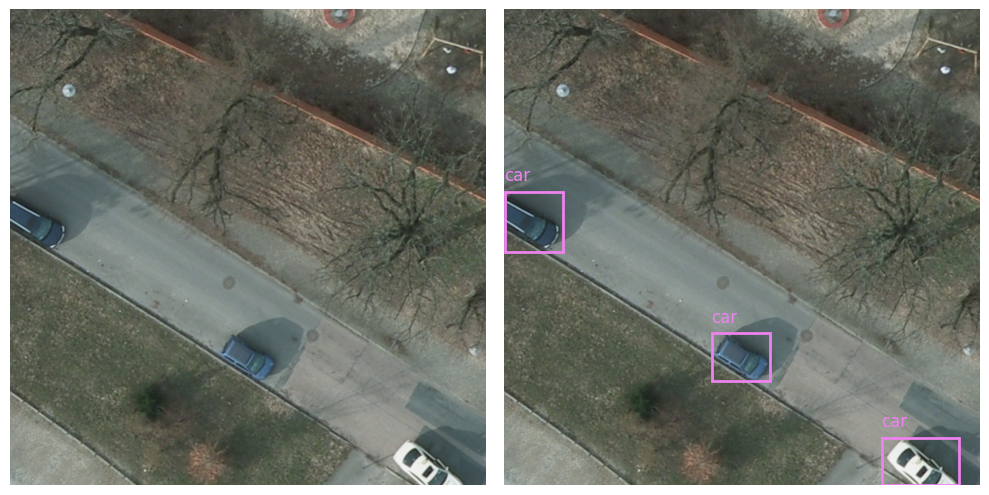

In [21]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/",
    "csv_file": "/home/dragik/data/FAIR_EO/artifive-potsdam/artifive_potsdam_train.csv",
    "selection": "all",
}
dataset = ArtifiVePotsdamDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1005)
dataset.show_image(10)
dataset.show_image(200);

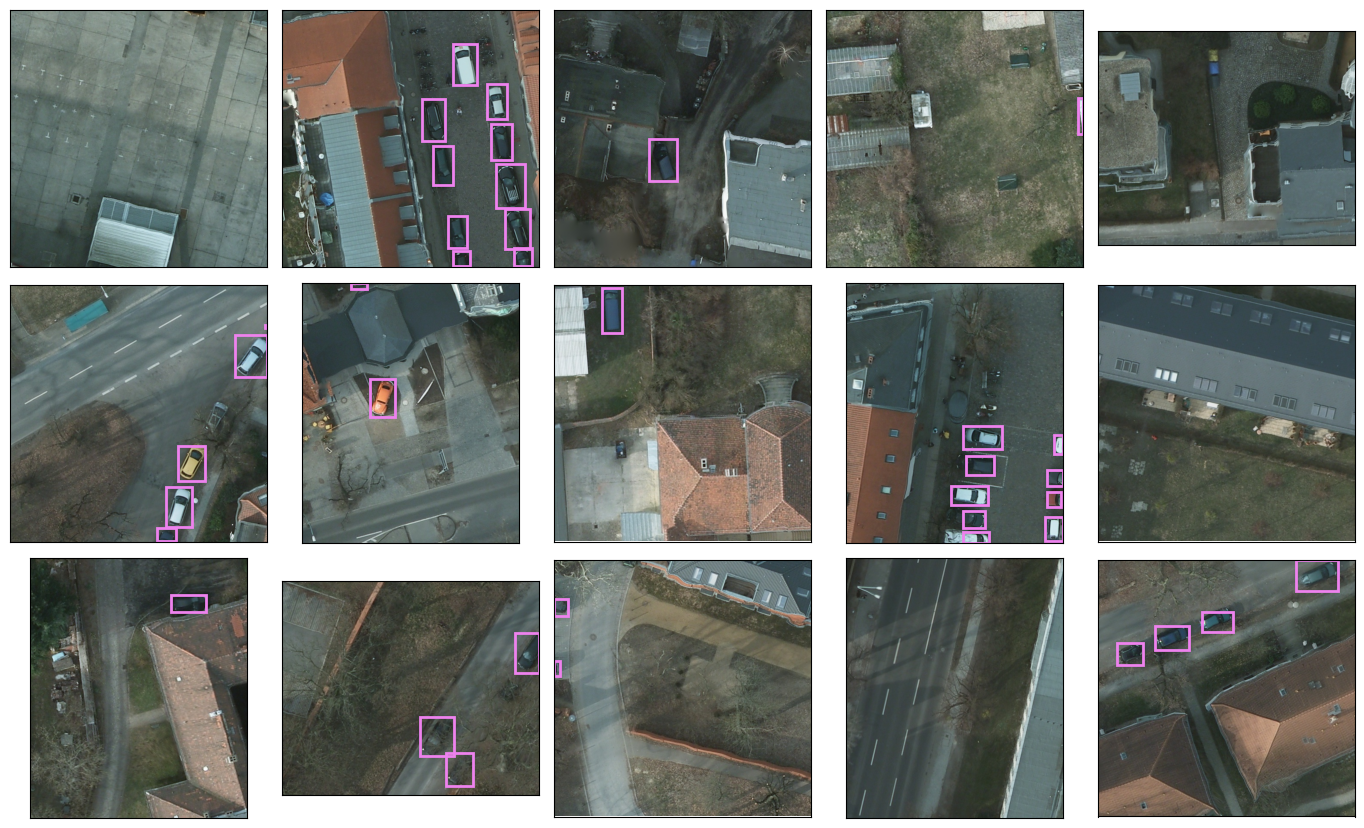

In [17]:
dataset.show_batch(15);

In [9]:
dataset.data_distribution_table()

,Label,Count
0,Car,6978


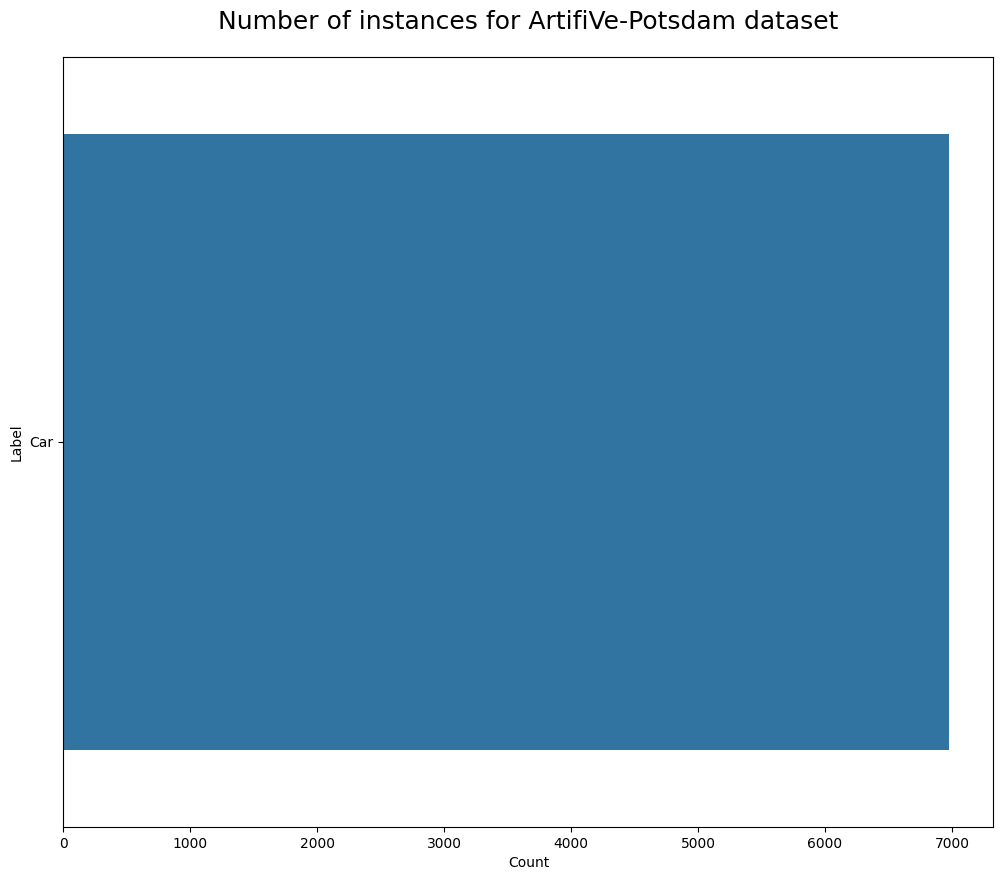

In [12]:
dataset.data_distribution_barchart();

## Load train data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/",
    "csv_file": "/home/dragik/data/FAIR_EO/artifive-potsdam/artifive_potsdam_train.csv",
    "selection" : "/", # exclude images without bounding boxes
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = ArtifiVePotsdamDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1354


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [24]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-01-12 14:26:41,199 INFO Starting training.
training: 100%|██████████| 170/170 [02:20<00:00,  1.21it/s]
2026-01-12 14:29:02,034 INFO epoch: 1, time: 141, loss:  0.37107
testing on train set: 100%|██████████| 170/170 [01:08<00:00,  2.47it/s]
2026-01-12 14:30:16,879 INFO map:0.7064288258552551, map_50:0.9209370017051697, map_75:0.8339447975158691, map_small:0.3578748106956482, map_medium:0.7846706509590149, map_large:0.8340364098548889, mar_1:0.16326110064983368, mar_10:0.6907120943069458, mar_100:0.7464249134063721, mar_small:0.4218195378780365, mar_medium:0.8270944952964783, mar_large:0.8583333492279053, map_per_class:0.7064288258552551, mar_100_per_class:0.7464249134063721, classes:1.0
training: 100%|██████████| 170/170 [02:00<00:00,  1.41it/s]
2026-01-12 14:32:17,810 INFO epoch: 2, time: 121, loss:  0.26824
testing on train set: 100%|██████████| 170/170 [01:24<00:00,  2.00it/s]
2026-01-12 14:33:46,952 INFO map:0.739361584186554, map_50:0.9357641935348511, map_75:0.861654877662658

0.11987914224230908

## Evaluate the model

In [27]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/",
    "csv_file": "/home/dragik/data/FAIR_EO/artifive-potsdam/artifive_potsdam_val.csv",
    "selection": "/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = ArtifiVePotsdamDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 474


2026-01-13 07:59:20,813 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar
2026-01-13 07:59:21,174 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 60/60 [00:19<00:00,  3.05it/s]


[{'map': 0.6960576176643372,
  'map_50': 0.9136319756507874,
  'map_75': 0.8207098841667175,
  'map_small': 0.40876680612564087,
  'map_medium': 0.7575942873954773,
  'map_large': 0.3899340033531189,
  'mar_1': 0.15624502301216125,
  'mar_10': 0.6831742525100708,
  'mar_100': 0.7386236786842346,
  'mar_small': 0.46448802947998047,
  'mar_medium': 0.8013190031051636,
  'mar_large': 0.42500001192092896,
  'map_per_class': 0.6960576176643372,
  'mar_100_per_class': 0.7386236786842346,
  'classes': 1.0}]

## Predictions

2026-01-13 08:06:20,066 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar
2026-01-13 08:06:20,604 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar at epoch 11


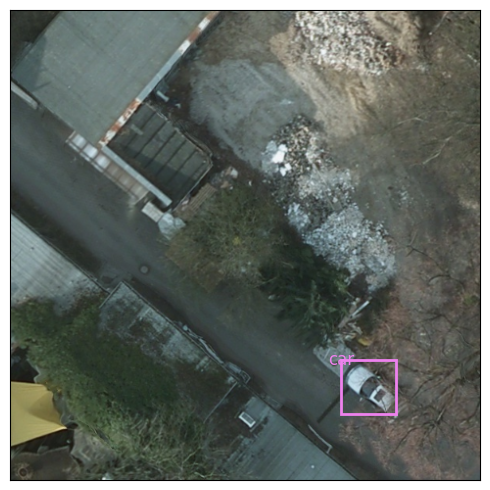

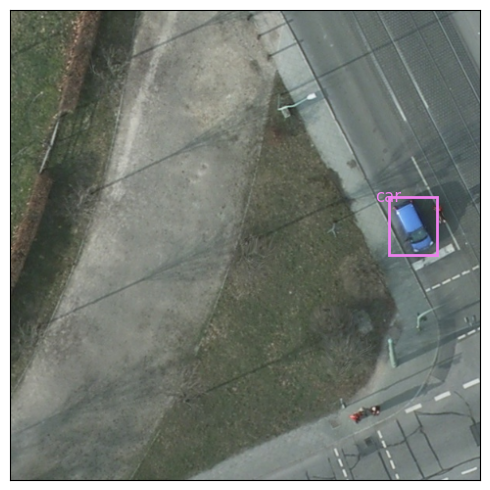

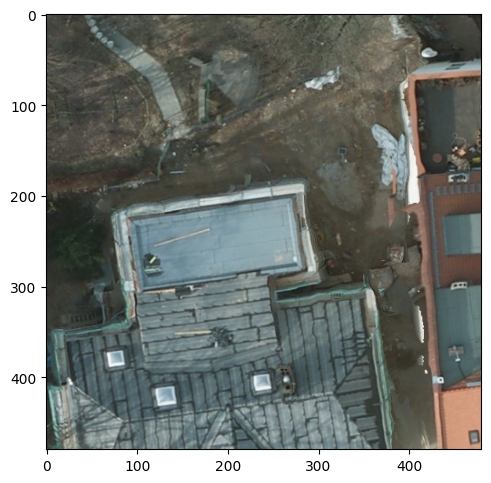

In [7]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/ArtifivePotsdam/checkpoint.pth.tar"
labels = ["no-data","car"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/test/top_potsdam_2_13_06_05_RGB.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/test/top_potsdam_2_13_01_08_RGB.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/artifive-potsdam/patched/600x600/test/top_potsdam_2_13_05_06_RGB.jpg')
fig = model.detect_objects(image, labels, transform)